## Explore Dataset

In [1]:
from ipywidgets import interact, IntSlider
import importlib
import geopandas as gpd
import folium
import dotenv
import os
import pandas as pd
import networkx as nx
import shapely
import numpy as np
import RiskMap
import matplotlib.pyplot as plt
from collections.abc import Callable
import momepy as mp

from utils import csoRisk
from utils import consentsRisk

import utils.graph
importlib.reload(utils.graph)
importlib.reload(utils.rivers)
importlib.reload(consentsRisk)
importlib.reload(csoRisk)

importlib.reload(gpd)

importlib.reload(RiskMap)
dotenv.load_dotenv(override=True)

True

## Obtaining data

Keeping all the data in the EPSG 3857 coordinate referencing system (CRS) to work better with distances

### CSO Data

In [ ]:
# geo_JSON_url = "https://services-eu1.arcgis.com/MSNNjkZ51iVh8yBj/arcgis/rest/services/Northumbrian_Water_Storm_Overflow_Activity_2_view/FeatureServer/0/query?outFields=*&where=1%3D1&f=geojson"
# cso: gpd.GeoDataFrame = gpd.read_file(geo_JSON_url)
# cso_all = cso.to_crs(epsg=27700)

In [ ]:
# INPUT_PATH = os.getenv("CSO_DATA_PATH")
# if INPUT_PATH is None:
#     raise ValueError("Input Path not set")
# bucketName = INPUT_PATH.split("/")[2]
# path_in_bucket = '/'.join(INPUT_PATH.split("/")[3:])
# storage_client = storage.Client()
# bucket = storage_client.get_bucket(bucketName)
# geojson_filenames = ["gs://"+bucketName+'/' +
#                      fname.name for fname in bucket.list_blobs(prefix=path_in_bucket) if fname.name.endswith('.geojson')]
# cso = gpd.read_file(geojson_filenames[-1])
# cso_all = cso.to_crs(epsg=27700)

In [4]:
cso_all = gpd.read_parquet(
    "gs://rdmai_dev_data/cleansed/Theme2CD/CSO_Annual_2024_Weir.parquet")

### SSSI data

In [ ]:
SSSI_PATH = os.getenv("SSSI_DATA_PATH")
sssi_all = gpd.read_file(SSSI_PATH)

### Bathing Water data

In [ ]:
BATHW_PATH = os.getenv("BATHW_DATA_PATH")
bathw_all = gpd.read_file(BATHW_PATH).to_crs(epsg=27700)

### WwTW data

In [5]:
WWTW_PATH = os.getenv("WWTW_DATA_PATH")
wwtw_all = gpd.read_parquet(WWTW_PATH)

### River data

In [6]:
RIVERS_PATH = os.getenv("RIVERS_PATH")
rivers = gpd.read_file(RIVERS_PATH)
rivers = rivers.to_crs(epsg=27700)
rivers_all = rivers.copy()

### Clip to Catchment Data

In [7]:
cmnt = gpd.read_file(
    "https://environment.data.gov.uk/catchment-planning/OperationalCatchment/3052.geojson"
)  # Browney
# cmnt = gpd.read_file(
#     "https://environment.data.gov.uk/catchment-planning/WaterBody/GB103023075780.geojson"
# )  # Ousburn
# cmnt = gpd.read_file(
#     "https://environment.data.gov.uk/catchment-planning/ManagementCatchment/3110.geojson"
# )
cmnt.to_crs(cso_all.crs, inplace=True)

In [18]:
cmnt.to_crs(epsg=4326).total_bounds

array([-1.75926729, 54.97627333, -1.52526845, 55.04531808])

In [8]:
rivers = gpd.clip(rivers_all, cmnt)
# Remove all rivers that aren't LineStrings after Clipping
rivers = rivers[rivers.geometry.apply(
    lambda x: isinstance(x, shapely.LineString))]
cso = gpd.clip(cso_all, cmnt)
wwtw = gpd.clip(wwtw_all, cmnt)

In [ ]:
bathw = bathw_all.clip(cmnt.total_bounds)
sssri = gpd.clip(sssi_all, cmnt)


def collection(x):
    if isinstance(x, shapely.GeometryCollection):
        return list(x.geoms)
    else:
        return [x]


sssri["geometry2"] = sssri.geometry.apply(
    lambda x: [poly for poly in collection(x) if isinstance(poly, shapely.Polygon)])
sssri = sssri.explode("geometry2").set_geometry(
    "geometry2").set_crs(sssi_all.crs)

## Construct Risk Info Map

In [9]:
RIVER_RESOLUTION: float = 200
MAX_OUTFALL_DIST_FROM_RIVER: float = 700
MAX_RISK_DISTANCE: float = np.inf

In [10]:
# Generate Graph from Rivers
riskmap = RiskMap.RiskMap(rivers, "OBJECTID", RIVER_RESOLUTION, directed=True)
riskmap.construct_river_graph()

In [11]:
# Add CSO information
outfallLocations = riskmap.add_point_info_to_map(
    cso.index, cso["geometry"], 'csoInfo', MAX_RISK_DISTANCE, MAX_OUTFALL_DIST_FROM_RIVER)
cso = cso.assign(outfallLocation=outfallLocations)

In [12]:
# Add WwTW information
outfallLocations = riskmap.add_point_info_to_map(
    wwtw.index, wwtw["EFFLUENT_LOC"], 'wwtwInfo',
    MAX_RISK_DISTANCE, MAX_OUTFALL_DIST_FROM_RIVER
)
wwtw = wwtw.assign(outfallLocation=outfallLocations)

In [13]:
def linear_dist_decrease(d: float) -> float:
    return (MAX_RISK_DISTANCE-d)/MAX_RISK_DISTANCE

In [14]:
# Construct and get the GDF
riskmap.add_all_risk(
    [
        {
            "info_col": "csoInfo",
            "risk_name": "csoRisk",
            "risk_method": consentsRisk.add_cso_P_risk,
            "aggregation_method": "w_avg",
            "distance_scaling": consentsRisk.P_distance_scaling,
        },
        {
            "info_col": "wwtwInfo",
            "risk_name": "wwtwRisk",
            "risk_method": consentsRisk.add_wwtw_P_risk,
            "aggregation_method": "w_avg",
            "distance_scaling": consentsRisk.P_distance_scaling,
        },
    ]
)

In [15]:
riskmap.construct_risk_map()
river_points = riskmap.get_risk_map()

## Explore

In [16]:
m = cmnt.explore(
    highlight=False,
    tooltip=False,
    popup=False,
    color="grey",
)
rivers.explore(
    m=m,
    color="blue",
)
river_points[river_points["Risk"] > 0][
    ["geometry", "Risk", 
     "csoRisk", 
     "wwtwRisk"
     ]
    ].explore(
    m=m,
    column="Risk",
    cmap='viridis',
    # vmax=200,
    marker_kwds={"radius": 5},
)
cso[["outfallLocation", "Weir Setting"]].set_geometry("outfallLocation").explore(
    m=m,
    color="pink",
    marker_kwds={"radius": 8}
)
wwtw.set_geometry("outfallLocation").explore(
    m=m,
    color="dark blue",
    marker_kwds={"radius": 8}
)

## Watershed delineation

In [29]:
riskmap.get_risk_map()["geometry"].to_crs(epsg=4326).to_file("./wbe/riskmap.shp")

In [30]:
gdf = gpd.read_file("./wbe/pourpoints_watershed.shp").to_crs(epsg=27700)
rmap = riskmap.get_risk_map()
rmap["idx"] = rmap.index

/opt/conda/envs/whitebox/lib/python3.10/site-packages/pyogrio/raw.py:198: RuntimeWarning: ./wbe/pourpoints_watershed.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


In [31]:
gdf.shape

(116, 3)

In [ ]:
m = folium.Map(location=[54.7, -1.6])
m = gdf.explore(m=m)
m = rmap.explore(m=m,color="red")
# m = cmnt.explore(m=m)
m

## Optimize Placement of Sensors

In [17]:
N_SENSORS = 10
COVERAGE_DIST = 2000
SEC82_COVERAGE_DIST = 500

In [59]:
def sensor_coverage(dist: float | np.ndarray) -> float | np.ndarray:
    def sigmoid(x):
        return 1/(1+np.exp(-(x+COVERAGE_DIST/2)/COVERAGE_DIST*10))
    
    points = np.linspace(-COVERAGE_DIST, 0, 10)
    return np.interp(dist,[0-COVERAGE_DIST, *points,0,10],
              [0, *sigmoid(points),1,0])

In [64]:
x = np.linspace(-2*COVERAGE_DIST, COVERAGE_DIST/2, 100)
y = sensor_coverage(x)

Text(0.5, 0, 'distance_downstream')

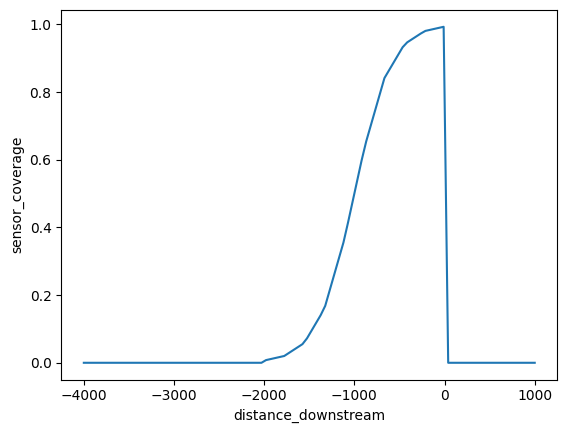

In [65]:
plt.plot(x, y)
plt.ylabel("sensor_coverage")
plt.xlabel("distance_downstream")

### Greedy

In [ ]:
history = riskmap.optimization_greedy(
    N_SENSORS,
    [
        {
            "info_col": "csoInfo",
            "risk_name": "csoRisk",
            "risk_method": csoRisk.add_duration_risk,
            "distance_scaling": linear_dist_decrease,
        }
    ],
    2000,
    hist=True,
)

In [ ]:
def plot(x):
    m = rivers.explore()

    if isinstance(history, tuple):
        history[0].explore(m=m, marker_kwds={"radius": 5}, color="red")
        riskmap.get_risk_map().explore(m=m, column=history[1])

    else:
        if len(history[x][0]) > 0:
            history[x][0].explore(m=m, marker_kwds={"radius": 5}, color="red")
        history[x][1].explore(m=m, column="Risk")
    return m


interact(plot, x=IntSlider(min=0, max=len(history)-1, step=1))

In [ ]:
sensorLocs = history[-1][0]
sensorLocs["ID"] = [f"S_{i}" for i in range(len(sensorLocs))]
netw = riskmap.get_river_network()

In [ ]:
utils.graph.integrate_field(netw, "Risk")

In [ ]:
sensorLocs.apply(
    lambda x: utils.graph.add_to_graph(
        netw,
        "sensorInfo",
        x["ID"],
        x["geometry"],
        None,
        COVERAGE_DIST,
        True,
        is_node=True,
    ),
    axis=1)
for n, data in netw.nodes(data=True):
    data["sensorCoverage"] = max([sensor_coverage(
        val) for key, val in data.get("sensorInfo", {}).items()], default=0)
utils.graph.integrate_nn_field_product(
    netw, "Risk", "sensorCoverage", "coveredRisk")

totalRisk = 0
for _, _, data in netw.edges(data=True):
    totalCovered += data["coveredRisk"]
    totalRisk += data["Risk_int"]
totalCovered/totalRisk

In [ ]:
utils.graph.integrate_field(netw, "Risk")

In [ ]:
p, e = mp.nx_to_gdf(netw)

In [ ]:
m = cmnt.explore(
    highlight=False,
    tooltip=False,
    popup=False,
    color="grey",
)
e.explore(
    m=m,
    # column="coveredRisk",
    column="coveredRisk",
    marker_kwds={"radius": 5},
)
sensors.explore(
    m=m,
    marker_kwds={"radius": 10},
)
# cso.set_geometry("outfallLocation").explore(
#     m=m,
#     color="red",
#     marker_kwds={"radius":6},
# )
p.explore(
    m=m,
    column="Risk",
    marker_kwds={"radius": 5},
    # marker_kwds=
)

### PyMoo

In [66]:
from pymoo.core.problem import ElementwiseProblem

from pymoo.operators.mutation.bitflip import BitflipMutation
from pymoo.operators.crossover.pntx import PointCrossover
from pymoo.operators.crossover.binx import BinomialCrossover
from pymoo.optimize import minimize
from pymoo.termination.ftol import MultiObjectiveSpaceTermination
from pymoo.termination.robust import RobustTermination
from pymoo.algorithms.moo.nsga2 import NSGA2

In [67]:
from pymoo.core.sampling import Sampling
from pymoo.core.mutation import Mutation

class FixedSensorSampling(Sampling):
    def __init__(self, n_sensors, n_nodes):
        super().__init__()
        self.n_sensors = n_sensors
        self.n_nodes = n_nodes

    def _do(self, problem, n_samples, **kwargs):
        X = np.zeros((n_samples, self.n_nodes), dtype=bool)
        for i in range(n_samples):
            sensor_indices = np.random.choice(
                self.n_nodes, self.n_sensors, replace=False)
            X[i, sensor_indices] = True
        return X

class Section82Sampling(Sampling):
    def __init__(self, riskmap: RiskMap.RiskMap,):
        super().__init__()
        self.riskmap = riskmap
        self.net = riskmap.get_river_network()
        self.gdf = riskmap.get_risk_map()
        utils.graph.difference_field(self.net, "Risk")

    # Can make this code more efficient but don't really need to
    def _do(self, problem, n_samples, **kwargs):
        # NOTE: Assumes a DiGraph
        X = np.zeros((n_samples, len(self.gdf)), dtype=int)
        # In riskmap, where there is riskdiff, insert a sensor above and below it
        for node, data in self.net.nodes(data=True):
            if data["Risk_diff"] > 0:
                for neighbor in self.net.predecessors(node):
                    neighbor_index = self.net.nodes[neighbor]["nodeID"]
                    X[0, neighbor_index] = 1
                for neighbor in self.net.successors(node):
                    neighbor_index = self.net.nodes[neighbor]["nodeID"]
                    X[0, neighbor_index] = 2
        for i in range(1,X.shape[0]):
            X[i] = X[i-1]
            for j in range(len(X[0])):
                if X[i-1][j] == 1:
                    p = self.gdf.loc[j,"geometry"]
                    if len(list(self.net.predecessors((p.x,p.y))))>0:
                        X[i][j] = 0
                        for neighbor in self.net.predecessors((p.x,p.y)):
                            neighbor_index = self.net.nodes[neighbor]["nodeID"]
                            if X[i][neighbor_index] == 2:
                                break
                            X[i][neighbor_index] = 1
                elif X[i-1][j] == 2:
                    p = self.gdf.loc[j,"geometry"]
                    if len(list(self.net.successors((p.x,p.y))))>0:
                        X[i][j] = 0
                        for neighbor in self.net.successors((p.x,p.y)):
                            neighbor_index = self.net.nodes[neighbor]["nodeID"]
                            if X[i][neighbor_index] == 1:
                                break
                            X[i][neighbor_index] = 2
        X = X.astype(bool)
        return X

class SensorMutation(Mutation):

    def __init__(self, flipprob, moveprob, adjMat: np.ndarray):
        super().__init__(flipprob)
        self.flipprob = flipprob
        self.moveprob = moveprob
        self.adj = adjMat
                
    def _do(self, problem, X, **kwargs):
        Xp = np.copy(X)
        flip = np.random.random(X.shape) < self.flipprob
        Xp[flip] = ~X[flip]
        
        # Move sensors
        move = (np.random.random(Xp.shape) < self.moveprob) & Xp
        succ = (self.adj[np.newaxis,:,:] & move[:,:,np.newaxis]).sum(axis=1)
        pred = (self.adj[np.newaxis,:,:] & move[:,np.newaxis,:]).sum(axis=2)
        
        # Move all either foward or backward
        Xp[move] = False
        which = succ if np.random.random()<0.5 else pred
        Xp = Xp | which
        return Xp.astype('bool')

In [68]:
nsensors_82 = sum(Section82Sampling(riskmap)._do(None, 1)[0])

In [69]:
class MyProblem(ElementwiseProblem):

    def __init__(self, riskmap: RiskMap.RiskMap):

        l = len(riskmap.get_risk_map())

        super().__init__(n_var=l, n_obj=2, n_ieq_constr=1,)
        self.riskmap = riskmap
        net = riskmap.get_river_network()
        utils.graph.difference_field(net, "Risk")
        self.net = net

    def coverage_by_sensors(self, x:list[bool], net:nx.DiGraph) -> float:
        sensorLocs = gpd.GeoDataFrame(self.riskmap.get_risk_map()[
                                    x]["geometry"], geometry="geometry")
        sensorLocs["ID"] = [f"S_{i}" for i in range(len(sensorLocs))]

        netw = net.copy()
        sensorLocs.apply(lambda x: utils.graph.add_to_graph(
            netw,
            "sensorInfo",
            x["ID"],
            x["geometry"],
            None,
            COVERAGE_DIST,
            True,
            is_node=True,
        ),
            axis=1)

        for _, data in netw.nodes(data=True):
            cov = max([sensor_coverage(val)
                    for _, val in data.get("sensorInfo", {}).items()], default=0)
            data["sensorCoverage"] = cov

        utils.graph.integrate_field(netw, "Risk")
        utils.graph.integrate_nn_field_product(
            netw, "sensorCoverage", "Risk",  "coveredRisk")

        totalCovered = 0
        totalRisk = 0
        for _, _, data in netw.edges(data=True):
            totalCovered += data["coveredRisk"]
            totalRisk += data["Risk_int"]
        return totalCovered/totalRisk, netw

    def sec82_coverage_by_sensors(self, x:list[bool], net:nx.DiGraph, coverage_dist:float) -> float:
        sensorLocs = gpd.GeoDataFrame(self.riskmap.get_risk_map()[
                                    x]["geometry"], geometry="geometry")
        sensorLocs["ID"] = [f"S_{i}" for i in range(len(sensorLocs))]

        netw = net.copy()
        utils.graph.func_field_n(netw,lambda x: x if x>0 else 0, "Risk_diff", "Risk_diff")
        sensorLocs.apply(lambda x: utils.graph.add_to_graph(
            netw,
            "sensorInfo",
            x["ID"],
            x["geometry"],
            None,
            COVERAGE_DIST,
            True,
            is_node=True,
        ),
            axis=1)

        for _, data in netw.nodes(data=True):
            closeAfter = np.inf
            closeBef = -np.inf
            sensinfo = data.get("sensorInfo", {})
            for k, val in sensinfo.items():
                if val<0:
                    closeBef = max(closeBef,val)
                if val>0:
                    closeAfter = min(closeAfter,val)
            # If sensor is present, only one of them needs to be in range
            if 0 in sensinfo.values():
                c = abs(closeAfter) < coverage_dist or abs(closeBef) <= coverage_dist
            # If sensor is not present, we need to check the distance between them
            else:
                c = closeAfter-closeBef <= coverage_dist
            data["sensorCoverage"] = int(c)
        
        totalCovered = 0
        totalRisk = 0
                
        for node in netw.nodes:
            totalRisk += netw.nodes[node].get("Risk_diff",0)
            netw.nodes[node]["coveredRisk"] = netw.nodes[node].get("Risk_diff",0)*netw.nodes[node].get("sensorCoverage",0)
            totalCovered += netw.nodes[node]["coveredRisk"]
        return totalCovered/totalRisk, netw

    def change_coverage_by_sensors(self, x:list[bool], net:nx.DiGraph) -> float:
        sensorLocs = gpd.GeoDataFrame(self.riskmap.get_risk_map()[
                                      x]["geometry"], geometry="geometry")
        sensorLocs["ID"] = [f"S_{i}" for i in range(len(sensorLocs))]

        netw = net.copy()
        utils.graph.func_field_n(netw,lambda x: x if x>0 else 0, "Risk_diff", "Risk_diff")
        sensorLocs.apply(lambda x: utils.graph.add_to_graph(
            netw,
            "sensorInfo",
            x["ID"],
            x["geometry"],
            None,
            COVERAGE_DIST,
            True,
            is_node=True,
        ),
            axis=1)

        for _, data in netw.nodes(data=True):
            cov = max([sensor_coverage(val)
                      for _, val in data.get("sensorInfo", {}).items()], default=0)
            data["sensorCoverage"] = cov

        totalCovered = 0
        totalRisk = 0

        for node in netw.nodes:
            totalRisk += netw.nodes[node].get("Risk_diff", 0)
            netw.nodes[node]["coveredRisk"] = netw.nodes[node].get(
                "Risk_diff", 0)*netw.nodes[node].get("sensorCoverage", 0)
            totalCovered += netw.nodes[node]["coveredRisk"]
        return totalCovered/totalRisk, netw

    def distance_from_each_other(self, x:list[bool]) -> float:
        sensorLocs = gpd.GeoDataFrame(self.riskmap.get_risk_map()[
                                      x]["geometry"], geometry="geometry")
        ps = np.stack([sensorLocs.geometry.x, sensorLocs.geometry.y], axis=1)
        distmat = scipy.spatial.distance.pdist(ps)
        if len(distmat):
            return np.mean(distmat)
        else:
            return 0

    def cost(self, x:list[bool]) -> float:
        return np.sum(x)

    def _evaluate(self, x, out, *args, **kwargs):
        out["F"] = [
            -self.change_coverage_by_sensors(x,self.net)[0],                    # Maximize
            self.cost(x),                                                       # Minimize
            # -self.distance_from_each_other(x),# Maximize
        ]
        out["G"] = sum(x) - N_SENSORS

In [101]:
algorithm = NSGA2(
    pop_size=100,
    n_offsprings=100,
    sampling=FixedSensorSampling(min(5*N_SENSORS,len(riskmap.get_risk_map())), len(riskmap.get_risk_map())),
    # sampling=Section82Sampling(riskmap),
    # crossover=BinomialCrossover(),
    crossover=PointCrossover(n_points=100),
    # mutation=BitflipMutation(prob=0.01,),
    mutation=SensorMutation(flipprob=0.01, moveprob=0.05, adjMat = nx.to_numpy_array(riskmap.get_river_network(),dtype='bool')),
    eliminate_duplicates=True
)
problem = MyProblem(
    riskmap,
)

In [102]:
res = minimize(
    problem,
    algorithm,
    termination=RobustTermination(
        MultiObjectiveSpaceTermination(tol=0.01), 20),
    # save_history=True,
    verbose=True,
)

n_gen  |  n_eval  | n_nds  |     cv_min    |     cv_avg    |      eps      |   indicator  
     1 |      100 |      1 |  4.000000E+01 |  4.000000E+01 |             - |             -
     2 |      200 |      1 |  2.900000E+01 |  3.820000E+01 |             - |             -
     3 |      300 |      1 |  2.400000E+01 |  3.439000E+01 |             - |             -
     4 |      400 |      1 |  2.400000E+01 |  3.075000E+01 |             - |             -
     5 |      500 |      1 |  1.900000E+01 |  2.687000E+01 |             - |             -
     6 |      600 |      1 |  1.500000E+01 |  2.314000E+01 |             - |             -
     7 |      700 |      1 |  1.100000E+01 |  1.989000E+01 |             - |             -
     8 |      800 |      1 |  9.0000000000 |  1.653000E+01 |             - |             -
     9 |      900 |      1 |  6.0000000000 |  1.332000E+01 |             - |             -
    10 |     1000 |      1 |  3.0000000000 |  1.022000E+01 |             - |             -

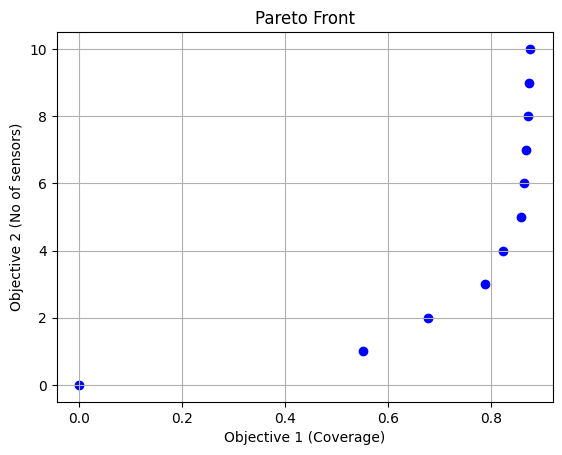

In [113]:
pareto_front = res.F

# Plot the Pareto front
plt.scatter(-pareto_front[:, 0], pareto_front[:, 1], c='blue')
plt.title('Pareto Front')
plt.xlabel('Objective 1 (Coverage)')
plt.ylabel('Objective 2 (No of sensors)')
plt.grid(True)
plt.show()

In [114]:
resF = []
n_check = N_SENSORS+1
while not len(resF):
    n_check -=1
    resF = res.F[res.F[:,1]==n_check]
    resX = res.X[res.F[:,1]==n_check]
idx = np.argmin(resF[:,0])

In [115]:

net = riskmap.get_river_network()
utils.graph.difference_field(net, "Risk")
ratio, netw = problem.change_coverage_by_sensors(resX[idx], net)
sensorLocs = riskmap.get_risk_map()[resX[idx]]["geometry"]
ratio,resF[idx]

(np.float64(0.8760714778859611), array([-0.87607148, 10.        ]))

In [116]:
utils.graph.integrate_field(netw, "Risk")
p, e = mp.nx_to_gdf(netw)
X = Section82Sampling(riskmap)._do(None, 10)

In [117]:
m = cmnt.explore(
    highlight=False,
    tooltip=False,
    popup=False,
    color="grey",
)
# e.explore(
#     m=m,
#     # column="coveredRisk",
#     column="Risk_diff",
#     marker_kwds={"radius": 5},
# )
sensorLocs.explore(
    m=m,
    color="green",
    marker_kwds={"radius": 10},
)
# cso[["outfallLocation"]].set_geometry("outfallLocation").explore(
#     m=m,
#     color="red",
#     marker_kwds={"radius":6},
# )
# wwtw.set_geometry("outfallLocation").explore(
#     m=m,
#     color = "blue",
#     marker_kwds={"radius": 8}
# )
p[["geometry","Risk_diff","Risk","sensorCoverage"]].explore(
    m=m,
    column="Risk_diff",
    marker_kwds={"radius": 4},
    vmax = 100,
    # marker_kwds=
)
# riskmap.get_risk_map().loc[X[0]].explore(m=m, color="white",
#                                          marker_kwds={"radius": 10})